In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent

DATASET_ROOT = PROJECT_ROOT / "dataset" / "Deepfake"

METADATA_ROOT = (
    PROJECT_ROOT
    / "dataset"
    / "deepfake_metadata"
)

TRAIN_CSV = METADATA_ROOT / "train_metadata.csv"
DEV_CSV = METADATA_ROOT / "dev_metadata.csv"
EVAL_CSV = METADATA_ROOT / "eval_metadata.csv"

print("Project root:")
print(PROJECT_ROOT)

print("\nDataset root:")
print(DATASET_ROOT)

print("\nMetadata root:")
print(METADATA_ROOT)

Project root:
c:\Users\abi66\OneDrive\Desktop\VoiceShield AI

Dataset root:
c:\Users\abi66\OneDrive\Desktop\VoiceShield AI\dataset\Deepfake

Metadata root:
c:\Users\abi66\OneDrive\Desktop\VoiceShield AI\dataset\deepfake_metadata


In [4]:
train_df = pd.read_csv(TRAIN_CSV)
dev_df = pd.read_csv(DEV_CSV)
eval_df = pd.read_csv(EVAL_CSV)

print("Train shape:", train_df.shape)
print("Dev shape:", dev_df.shape)
print("Eval shape:", eval_df.shape)

Train shape: (25380, 7)
Dev shape: (7359, 7)
Eval shape: (71237, 7)


In [5]:
train_df.head()

,audio_path,utterance_id,speaker_id,attack_id,label,label_name,split
0,dataset\Deepfake\ASVspoof2019_LA_train\flac\LA...,LA_T_1138215,LA_0079,-,0,bonafide,train
1,dataset\Deepfake\ASVspoof2019_LA_train\flac\LA...,LA_T_1271820,LA_0079,-,0,bonafide,train
2,dataset\Deepfake\ASVspoof2019_LA_train\flac\LA...,LA_T_1272637,LA_0079,-,0,bonafide,train
3,dataset\Deepfake\ASVspoof2019_LA_train\flac\LA...,LA_T_1276960,LA_0079,-,0,bonafide,train
4,dataset\Deepfake\ASVspoof2019_LA_train\flac\LA...,LA_T_1341447,LA_0079,-,0,bonafide,train


In [6]:
print("TRAIN")
print(train_df["label_name"].value_counts())

print("\nDEV")
print(dev_df["label_name"].value_counts())

print("\nEVAL")
print(eval_df["label_name"].value_counts())

TRAIN
label_name
spoof       22800
bonafide     2580
Name: count, dtype: int64

DEV
label_name
spoof       6624
bonafide     735
Name: count, dtype: int64

EVAL
label_name
spoof       63882
bonafide     7355
Name: count, dtype: int64


In [7]:
print(train_df["label"].value_counts())

label
1    22800
0     2580
Name: count, dtype: int64


In [8]:
def check_files(df):

    exists = []

    for path in df["audio_path"]:

        full_path = PROJECT_ROOT / path

        exists.append(
            full_path.exists()
        )

    return pd.Series(exists)


train_exists = check_files(train_df)
dev_exists = check_files(dev_df)
eval_exists = check_files(eval_df)

print(
    "Train missing:",
    (~train_exists).sum()
)

print(
    "Dev missing:",
    (~dev_exists).sum()
)

print(
    "Eval missing:",
    (~eval_exists).sum()
)

Train missing: 0
Dev missing: 0
Eval missing: 0


In [13]:
print(
    "Sample rates:",
    Counter(sample_rates)
)

print(
    "Channels:",
    Counter(channels)
)

print(
    "Failed files:",
    len(failed)
)

print(
    "Average duration:",
    np.mean(durations)
)

print(
    "Minimum duration:",
    np.min(durations)
)

print(
    "Maximum duration:",
    np.max(durations)
)

NameError: name 'sample_rates' is not defined

In [10]:
TARGET_SAMPLE_RATE = 16000


def preprocess_audio(
    audio_path,
    target_sr=TARGET_SAMPLE_RATE
):

    # Load audio
    audio, sr = librosa.load(
        str(audio_path),
        sr=None,
        mono=True
    )

    # Resample
    if sr != target_sr:

        audio = librosa.resample(
            audio,
            orig_sr=sr,
            target_sr=target_sr
        )

        sr = target_sr

    # Normalize amplitude
    max_value = np.max(
        np.abs(audio)
    )

    if max_value > 0:

        audio = (
            audio / max_value
        )

    return audio, sr

In [11]:
sample_row = train_df.iloc[0]

sample_path = (
    PROJECT_ROOT
    / sample_row["audio_path"]
)

print("File:")
print(sample_path)

print(
    "\nLabel:",
    sample_row["label_name"]
)

File:
c:\Users\abi66\OneDrive\Desktop\VoiceShield AI\dataset\Deepfake\ASVspoof2019_LA_train\flac\LA_T_1138215.flac

Label: bonafide


In [12]:
audio, sr = preprocess_audio(
    sample_path
)

print(
    "Processed sample rate:",
    sr
)

print(
    "Number of samples:",
    len(audio)
)

print(
    "Duration:",
    len(audio) / sr,
    "seconds"
)

print(
    "Maximum amplitude:",
    np.max(
        np.abs(audio)
    )
)

c:\Users\abi66\OneDrive\Desktop\VoiceShield AI\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Processed sample rate: 16000
Number of samples: 55329
Duration: 3.4580625 seconds
Maximum amplitude: 1.0


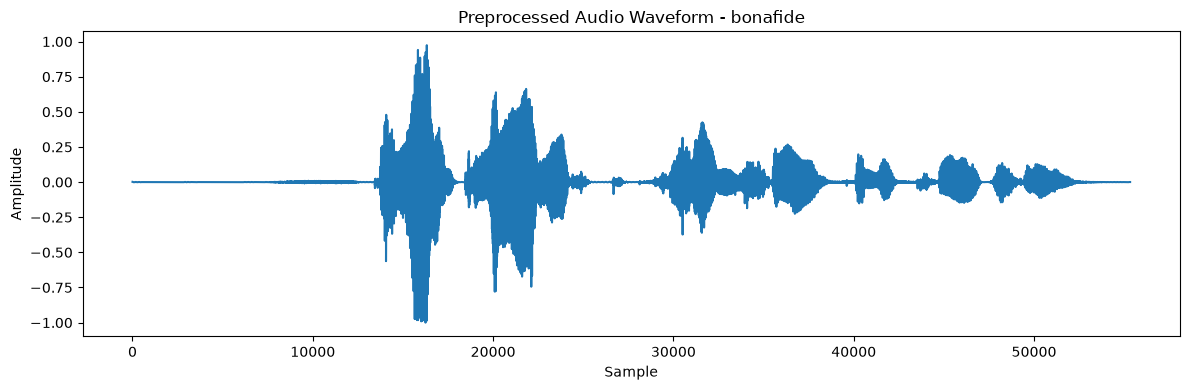

In [14]:
plt.figure(figsize=(12, 4))

plt.plot(audio)

plt.title(
    f"Preprocessed Audio Waveform - "
    f"{sample_row['label_name']}"
)

plt.xlabel(
    "Sample"
)

plt.ylabel(
    "Amplitude"
)

plt.tight_layout()

plt.show()